# Task 3: Clustering Analysis

## Objective
This task aims to identify underlying patterns in the Australian weather dataset using unsupervised learning.

We apply K-means and Hierarchical Clustering to the preprocessed weather features, evaluate their performance using multiple clustering metrics, and compare the resulting clusters.

The relationship between the identified clusters and actual rainfall patterns is also investigated.



## Section 1 — Data Loading and Sampling

The preprocessed dataset from Task 1 contains 142,193 observations and 115 features.

To reduce the computational cost of clustering, a stratified sample of 3,000 observations is selected using a fixed random seed.

The target variable, RainTomorrow, is excluded from clustering and is only used for sampling and subsequent interpretation.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# 1. Load preprocessed data
X = pd.read_csv("data/X_scaled_cleaned.csv")
y = pd.read_csv("data/y_cleaned.csv")["RainTomorrow"]

# 2. Inspect the dataset
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values:", X.isna().sum().sum())
print("Class distribution:")
print(y.value_counts(normalize=True))

# 3. Stratified sampling
X_sample, _, y_sample, _ = train_test_split(
    X,
    y,
    train_size=3000,
    stratify=y,
    random_state=42
)

# 4. Reset indices
X_sample = X_sample.reset_index(drop=True)
y_sample = y_sample.reset_index(drop=True)

print("\nSampled X shape:", X_sample.shape)
print("Sampled y shape:", y_sample.shape)
print("Sample class distribution:")
print(y_sample.value_counts(normalize=True))

X shape: (142193, 115)
y shape: (142193,)
Missing values: 0
Class distribution:
RainTomorrow
0    0.775819
1    0.224181
Name: proportion, dtype: float64

Sampled X shape: (3000, 115)
Sampled y shape: (3000,)
Sample class distribution:
RainTomorrow
0    0.775667
1    0.224333
Name: proportion, dtype: float64


## Section 2 — K-means Clustering

### 2.1 Baseline K-means (K=2)

K-means clustering is applied as a baseline method to group weather observations based on feature similarity.

We initially set the number of clusters to K=2 and use a fixed random seed for reproducibility.

In [33]:
from sklearn.cluster import KMeans

# Create the K-means model
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Fit the model and obtain cluster labels
kmeans_labels = kmeans.fit_predict(X_sample)

# Check the clustering results
print("Cluster labels:", kmeans_labels[:20])
print("\nNumber of samples in each cluster:")
print(pd.Series(kmeans_labels).value_counts())

Cluster labels: [1 0 1 0 0 0 1 1 1 1 1 0 1 0 0 1 1 0 0 0]

Number of samples in each cluster:
1    1731
0    1269
Name: count, dtype: int64


### 2.2 Baseline Evaluation

The clustering quality is evaluated using three internal validation metrics:

- **Silhouette Score:** Measures cluster cohesion and separation. Higher values indicate better-defined clusters.
- **Calinski-Harabasz Index:** Measures the ratio of between-cluster dispersion to within-cluster dispersion. Higher values are preferred.
- **Davies-Bouldin Index:** Measures cluster similarity based on within-cluster scatter and between-cluster separation. Lower values are preferred.

These metrics are used to assess the baseline K-means model and support subsequent comparisons.

In [34]:
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

# Evaluate K-means (K=2)
silhouette = silhouette_score(
    X_sample,
    kmeans_labels,
    sample_size=1000,
    random_state=42
)

ch_score = calinski_harabasz_score(
    X_sample,
    kmeans_labels
)

db_score = davies_bouldin_score(
    X_sample,
    kmeans_labels
)

print("K-means (K=2) Evaluation Results:")
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Calinski-Harabasz Index: {ch_score:.4f}")
print(f"Davies-Bouldin Index: {db_score:.4f}")

K-means (K=2) Evaluation Results:
Silhouette Score: 0.1386
Calinski-Harabasz Index: 537.3882
Davies-Bouldin Index: 2.2534


### 2.3 Cluster Number Selection (K=2–8)

To investigate the effect of cluster number on clustering performance, K-means is evaluated using different values of K, ranging from 2 to 8.

For each configuration, the Silhouette Score, Calinski-Harabasz Index, and Davies-Bouldin Index are calculated.

The results are compared to identify a suitable number of clusters.

In [35]:
# Experiment: K-means with different numbers of clusters

k_values = range(2, 9)

results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    sil = silhouette_score(
        X_sample,
        labels,
        sample_size=1000,
        random_state=42
    )

    ch = calinski_harabasz_score(X_sample, labels)
    db = davies_bouldin_score(X_sample, labels)

    results.append({
        "K": k,
        "Silhouette": sil,
        "Calinski-Harabasz": ch,
        "Davies-Bouldin": db
    })

kmeans_results_df = pd.DataFrame(results)

print("K-means Clustering Evaluation (K=2–8)")
display(kmeans_results_df.round(4))

K-means Clustering Evaluation (K=2–8)


,K,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.1386,537.3882,2.2534
1,3,0.1258,427.6761,2.3114
2,4,0.1013,349.3155,2.3920
3,5,0.1022,308.0319,2.1393
4,6,0.0793,283.5189,2.1898
5,7,0.0751,259.7429,2.2049
6,8,0.0768,242.5839,2.2223


### 2.4 Visualization of Evaluation Metrics

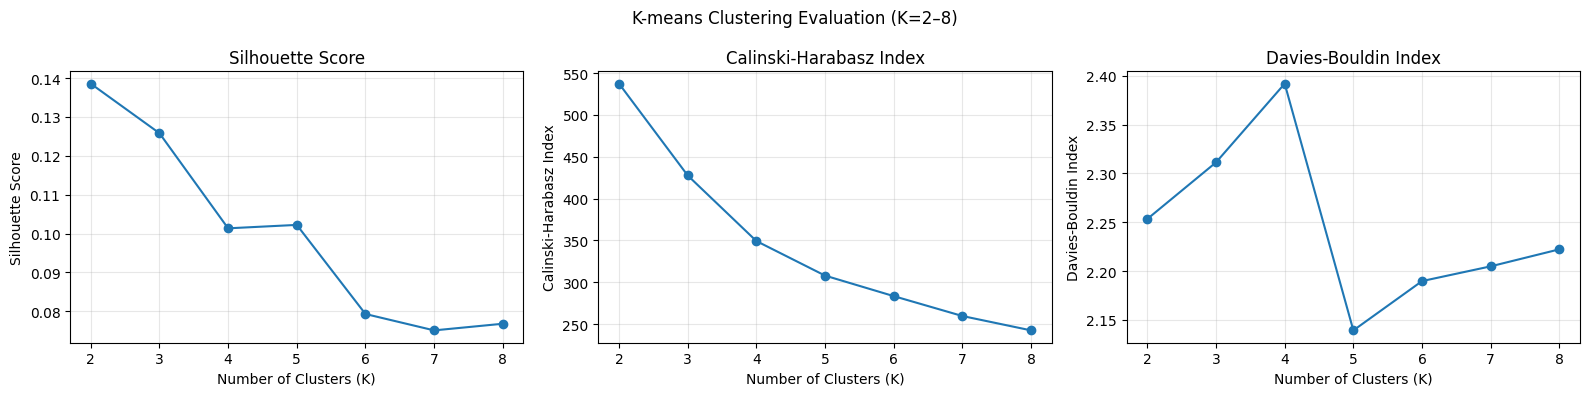

In [36]:
# Visualize K-means evaluation metrics across different K values

metrics = [
    ("Silhouette", "Silhouette Score"),
    ("Calinski-Harabasz", "Calinski-Harabasz Index"),
    ("Davies-Bouldin", "Davies-Bouldin Index")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (column, title) in zip(axes, metrics):
    ax.plot(
        kmeans_results_df["K"],
        kmeans_results_df[column],
        marker="o"
    )
    ax.set_title(title)
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)

plt.suptitle("K-means Clustering Evaluation (K=2–8)")
plt.tight_layout()
plt.show()

### 2.5 Results and Interpretation

The K-means clustering performance was evaluated for K values ranging from 2 to 8 using three internal validation metrics.

K=2 achieved the highest Silhouette Score (0.1386) and Calinski-Harabasz Index (537.3882), whereas K=5 achieved the lowest Davies-Bouldin Index (2.1393).

Although the evaluation metrics do not completely agree, K=2 is provisionally selected as the preferred configuration because it performs best on two of the three metrics and provides a simpler clustering structure.

However, the relatively low Silhouette Scores across all configurations suggest that the dataset does not exhibit strongly separated clusters under the current feature representation and clustering method. Further comparison with Hierarchical Clustering is therefore necessary.

## Section 3 — Hierarchical Clustering


### 3.1 Methodology

Agglomerative Hierarchical Clustering is selected as the second clustering algorithm to compare with K-means.

Unlike K-means, which partitions observations around cluster centroids, agglomerative clustering progressively merges similar observations or clusters.

Ward linkage is used to minimize the increase in within-cluster variance during each merging step.

The same 3,000 sampled observations and evaluation metrics are used to ensure a consistent comparison with K-means.

### 3.2 Baseline Hierarchical Clustering (K=2)

A baseline agglomerative clustering model is fitted using Ward linkage and two clusters.

The resulting cluster sizes are examined before evaluating clustering quality.

In [37]:
from sklearn.cluster import AgglomerativeClustering

# Create the Hierarchical Clustering model
hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

# Fit the model and obtain cluster labels
hierarchical_labels = hierarchical.fit_predict(X_sample)

# Check the clustering results
print("Cluster labels:", hierarchical_labels[:20])

print("\nNumber of samples in each cluster:")
print(pd.Series(hierarchical_labels).value_counts())

Cluster labels: [0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1]

Number of samples in each cluster:
0    2407
1     593
Name: count, dtype: int64


### 3.3 Baseline Evaluation

The baseline Hierarchical Clustering model is evaluated using the Silhouette Score, Calinski-Harabasz Index, and Davies-Bouldin Index.

The same evaluation settings as K-means are used to enable a fair comparison between the two clustering algorithms.

In [38]:
# Evaluate Hierarchical Clustering (K=2)

hier_silhouette = silhouette_score(
    X_sample,
    hierarchical_labels,
    sample_size=1000,
    random_state=42
)

hier_ch = calinski_harabasz_score(
    X_sample,
    hierarchical_labels
)

hier_db = davies_bouldin_score(
    X_sample,
    hierarchical_labels
)

print("Hierarchical Clustering (K=2) Evaluation Results:")
print(f"Silhouette Score: {hier_silhouette:.4f}")
print(f"Calinski-Harabasz Index: {hier_ch:.4f}")
print(f"Davies-Bouldin Index: {hier_db:.4f}")

Hierarchical Clustering (K=2) Evaluation Results:
Silhouette Score: 0.1347
Calinski-Harabasz Index: 377.2871
Davies-Bouldin Index: 2.1144


### 3.4 Cluster Number Selection (K=2–8)

To examine the effect of cluster number on Hierarchical Clustering, the number of clusters is varied from 2 to 8.

For each configuration, the same three internal validation metrics are calculated.

The results will be compared with those of K-means to identify a suitable clustering method and configuration.

In [39]:
# Experiment: Hierarchical Clustering with K=2 to 8

hier_results = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_sample)

    sil = silhouette_score(
        X_sample,
        labels,
        sample_size=1000,
        random_state=42
    )

    ch = calinski_harabasz_score(X_sample, labels)
    db = davies_bouldin_score(X_sample, labels)

    hier_results.append({
        "K": k,
        "Silhouette": sil,
        "Calinski-Harabasz": ch,
        "Davies-Bouldin": db
    })

hier_results_df = pd.DataFrame(hier_results)

print("Hierarchical Clustering Evaluation (K=2–8)")
display(hier_results_df.round(4))

Hierarchical Clustering Evaluation (K=2–8)


,K,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.1347,377.2871,2.1144
1,3,0.0733,326.7071,2.7312
2,4,0.0584,271.9636,2.9805
3,5,0.0630,239.9751,2.5750
4,6,0.0546,220.1777,2.5038
5,7,0.0597,207.0020,2.3464
6,8,0.0544,193.4951,2.4972


### 3.5 Visualization of Evaluation Metrics

The evaluation metrics are plotted against the number of clusters to examine how clustering quality changes as K increases.

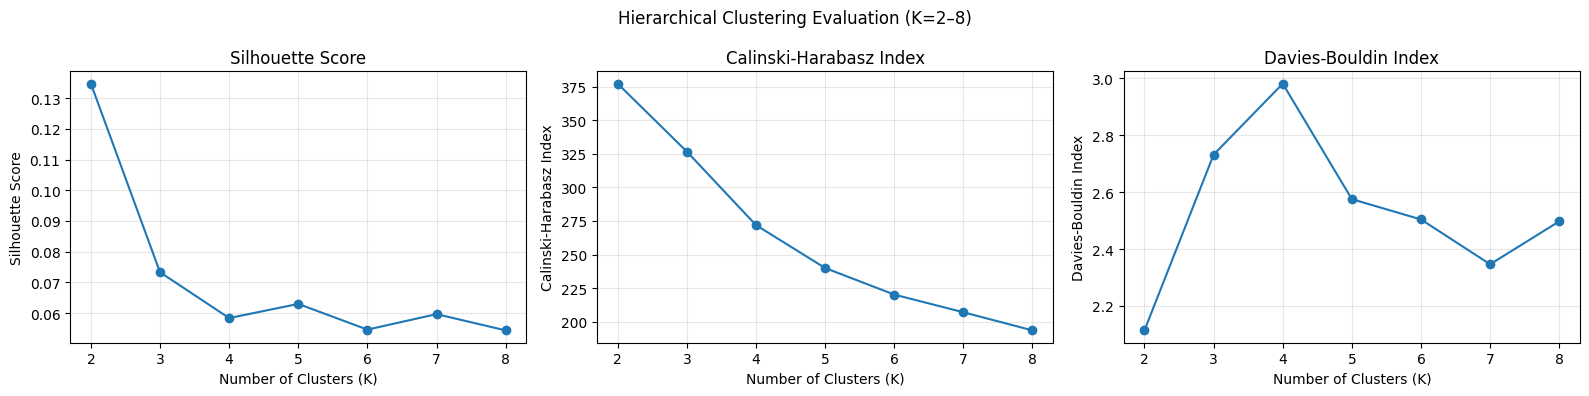

In [40]:
metrics = [
    ("Silhouette", "Silhouette Score"),
    ("Calinski-Harabasz", "Calinski-Harabasz Index"),
    ("Davies-Bouldin", "Davies-Bouldin Index")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (column, title) in zip(axes, metrics):
    ax.plot(
        hier_results_df["K"],
        hier_results_df[column],
        marker="o"
    )
    ax.set_title(title)
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)

plt.suptitle("Hierarchical Clustering Evaluation (K=2–8)")
plt.tight_layout()
plt.show()

### 3.6 Results and Interpretation

Hierarchical Clustering with Ward linkage was evaluated for K values ranging from 2 to 8.

Among the tested configurations, K=2 achieved the highest Silhouette Score (0.1347), the highest Calinski-Harabasz Index (377.2871), and the lowest Davies-Bouldin Index (2.1144).

The K=2 model produced two clusters containing 2,407 and 593 observations, respectively, indicating an uneven distribution of cluster sizes.

Although all three evaluation metrics favor K=2, the relatively low Silhouette Score suggests that the clusters are not strongly separated.

Therefore, K=2 is selected as the preferred Hierarchical Clustering configuration for subsequent comparison with K-means.

## Section 4 — Algorithm Comparison

### 4.1 Baseline Comparison (K=2)

### 4.1 Comparison of Clustering Performance

The preferred configurations of K-means and Hierarchical Clustering are compared using the same dataset and evaluation metrics.

Both methods favor K=2 under the current experimental setup, although their performance differs across evaluation metrics.

In [41]:
# Extract K=2 evaluation results from both algorithms
km_best = kmeans_results_df.loc[
    kmeans_results_df["K"] == 2
].copy()

hc_best = hier_results_df.loc[
    hier_results_df["K"] == 2
].copy()

# Add algorithm names
km_best["Algorithm"] = "K-means"
hc_best["Algorithm"] = "Hierarchical"

# Combine results into one comparison table
comparison_df = pd.concat(
    [km_best, hc_best],
    ignore_index=True
)

# Reorder columns
comparison_df = comparison_df[
    ["Algorithm", "K", "Silhouette",
     "Calinski-Harabasz", "Davies-Bouldin"]
]

display(comparison_df.round(4))

,Algorithm,K,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,K-means,2,0.1386,537.3882,2.2534
1,Hierarchical,2,0.1347,377.2871,2.1144


### 4.2 Results and Interpretation

The comparison shows that K-means (K=2) achieved a slightly higher Silhouette Score (0.1386 vs. 0.1347) and a higher Calinski-Harabasz Index (537.3882 vs. 377.2871) than Hierarchical Clustering.

However, Hierarchical Clustering achieved a lower Davies-Bouldin Index (2.1144 vs. 2.2534), indicating an advantage under this evaluation metric.

Overall, K-means is provisionally preferred because it performs better on two of the three evaluation metrics and is generally more computationally efficient for large datasets.

Nevertheless, the relatively low Silhouette Scores of both methods suggest that the weather observations do not form clearly separated clusters under the current experimental setup. Therefore, further visualization and rainfall pattern analysis are needed to assess the interpretability of the clustering results.

## 5. Clustering Visualization

### 5.1 PCA Projection

Principal Component Analysis (PCA) is applied to project the 115-dimensional weather dataset into a two-dimensional space for visualization.

PCA is used only for visualization. Both K-means and Hierarchical Clustering were trained on the original 115-dimensional preprocessed features.

The explained variance ratio is calculated to assess how much information is retained by the first two principal components.

In [42]:
from sklearn.decomposition import PCA

# Apply PCA to reduce 115 features to 2 dimensions
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_sample)

# Check the dimensionality and explained variance
print("Original data shape:", X_sample.shape)
print("PCA data shape:", X_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal explained variance:")
print(pca.explained_variance_ratio_.sum())

Original data shape: (3000, 115)
PCA data shape: (3000, 2)

Explained variance ratio:
[0.23291424 0.1440153 ]

Total explained variance:
0.3769295384424534


### 5.2 Visualization of K-means and Hierarchical Clustering

The clustering results of K-means and Hierarchical Clustering (K=2) are visualized using the same two-dimensional PCA projection.

Each point represents a weather observation, and its color indicates the cluster assigned by the corresponding algorithm.

Using identical PCA coordinates allows the clustering patterns produced by the two algorithms to be visually compared.

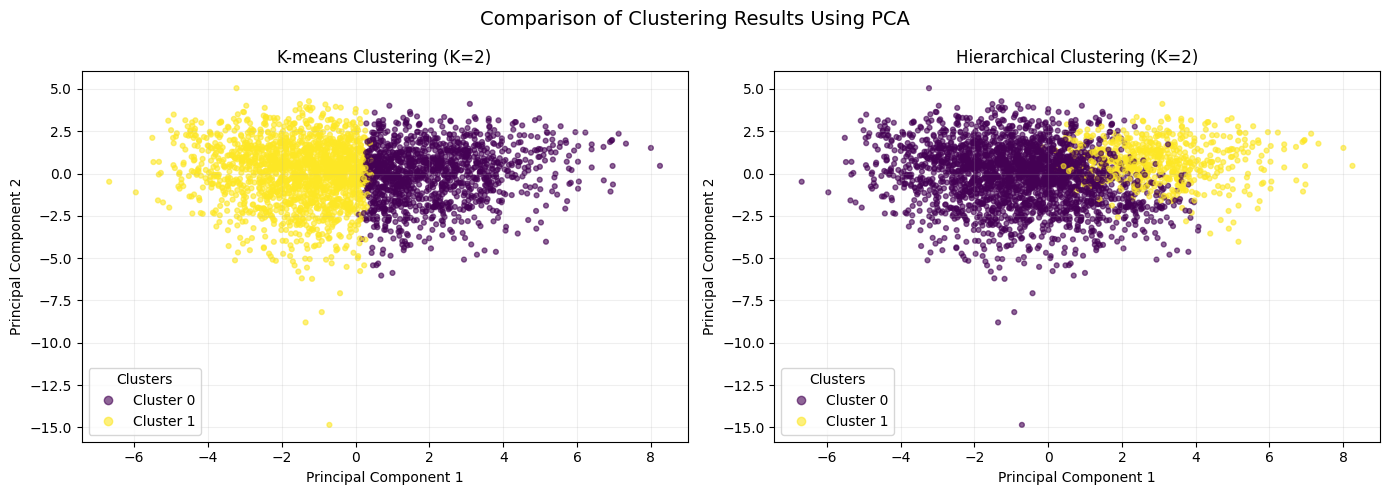

In [43]:
# Visualize clustering results using PCA

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-means
scatter1 = axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=12,
    alpha=0.6
)

axes[0].set_title("K-means Clustering (K=2)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].grid(alpha=0.2)

# Add legend for K-means
handles1, labels1 = scatter1.legend_elements()
axes[0].legend(
    handles1,
    ["Cluster 0", "Cluster 1"],
    title="Clusters"
)

# Hierarchical Clustering
scatter2 = axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=12,
    alpha=0.6
)

axes[1].set_title("Hierarchical Clustering (K=2)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].grid(alpha=0.2)

# Add legend for Hierarchical Clustering
handles2, labels2 = scatter2.legend_elements()
axes[1].legend(
    handles2,
    ["Cluster 0", "Cluster 1"],
    title="Clusters"
)

plt.suptitle(
    "Comparison of Clustering Results Using PCA",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 5.3 Visualization Analysis

The PCA visualizations reveal different clustering patterns between K-means and Hierarchical Clustering.

For K-means, the two clusters are primarily separated along the first principal component (PC1), with Cluster 1 concentrated on the left and Cluster 0 on the right. The clusters are relatively balanced in size, containing 1,731 and 1,269 observations, respectively.

In contrast, Hierarchical Clustering produces a more uneven distribution, with Cluster 0 containing 2,407 observations and Cluster 1 containing 593 observations. The smaller cluster is mainly concentrated in the region with higher PC1 values, while noticeable overlap occurs between the two clusters.

Although K-means exhibits a more visually distinct partition along PC1, the relatively low Silhouette Scores of both algorithms (0.1386 and 0.1347) suggest limited cluster separation in the original feature space.

The first two principal components explain 23.29% and 14.40% of the total variance, respectively, accounting for 37.69% in total. Therefore, the two-dimensional PCA projection provides only a partial representation of the original 115-dimensional data. The visualizations should be interpreted alongside the clustering evaluation metrics rather than being used alone to determine the better algorithm.

## 6. Rainfall Pattern Analysis

### 6.1 Rainfall Distribution Across Clusters

To investigate the relationship between the identified weather clusters and actual rainfall outcomes, the proportion of rainy days (RainTomorrow = 1) is calculated for each cluster.

The target labels were not used during clustering and are introduced only for post-clustering interpretation.

This analysis helps assess whether the unsupervised clusters correspond to meaningful differences in rainfall patterns.

In [44]:
# Combine cluster labels with actual rainfall outcomes

rainfall_df = pd.DataFrame({
    "RainTomorrow": y_sample,
    "KMeans_Cluster": kmeans_labels,
    "Hierarchical_Cluster": hierarchical_labels
})

# Calculate rainfall rate for each K-means cluster
kmeans_rainfall = rainfall_df.groupby(
    "KMeans_Cluster"
)["RainTomorrow"].agg(["count", "mean"])

kmeans_rainfall["Rainfall_Rate_%"] = (
    kmeans_rainfall["mean"] * 100
)

# Calculate rainfall rate for each Hierarchical cluster
hier_rainfall = rainfall_df.groupby(
    "Hierarchical_Cluster"
)["RainTomorrow"].agg(["count", "mean"])

hier_rainfall["Rainfall_Rate_%"] = (
    hier_rainfall["mean"] * 100
)

print("K-means Rainfall Distribution:")
display(kmeans_rainfall.round(2))

print("\nHierarchical Rainfall Distribution:")
display(hier_rainfall.round(2))

K-means Rainfall Distribution:


,count,mean,Rainfall_Rate_%
KMeans_Cluster,,,
0,1269,0.16,16.47
1,1731,0.27,26.81



Hierarchical Rainfall Distribution:


,count,mean,Rainfall_Rate_%
Hierarchical_Cluster,,,
0,2407,0.26,26.05
1,593,0.08,7.76


### 6.2 Visualization of Rainfall Rates

The proportion of observations with RainTomorrow = 1 is visualized for each cluster identified by K-means and Hierarchical Clustering.

This comparison helps examine whether the unsupervised clusters correspond to different rainfall patterns.

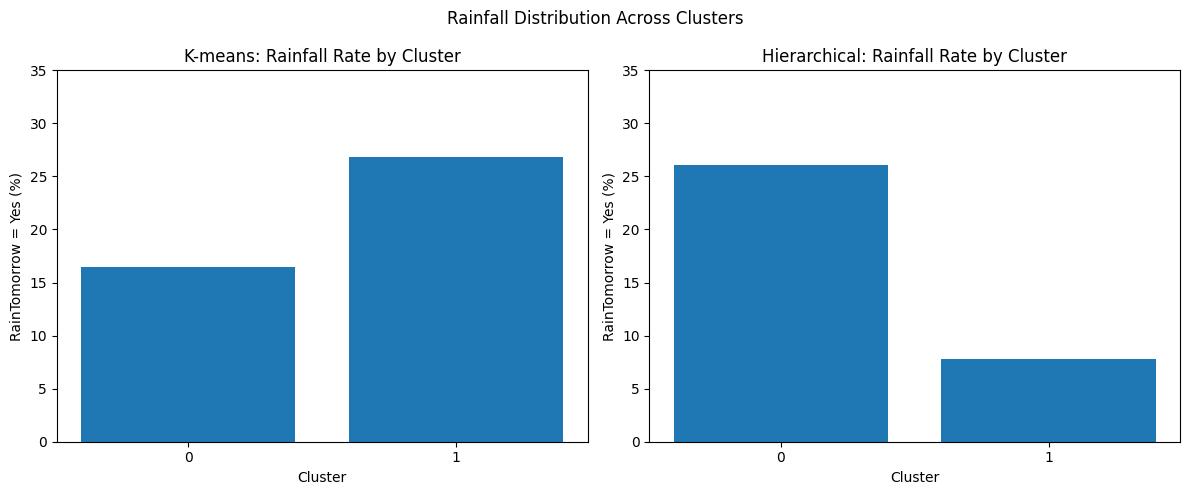

In [45]:
# Visualize rainfall rates across clusters

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# K-means rainfall rates
axes[0].bar(
    kmeans_rainfall.index.astype(str),
    kmeans_rainfall["Rainfall_Rate_%"]
)
axes[0].set_title("K-means: Rainfall Rate by Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("RainTomorrow = Yes (%)")
axes[0].set_ylim(0, 35)

# Hierarchical rainfall rates
axes[1].bar(
    hier_rainfall.index.astype(str),
    hier_rainfall["Rainfall_Rate_%"]
)
axes[1].set_title("Hierarchical: Rainfall Rate by Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("RainTomorrow = Yes (%)")
axes[1].set_ylim(0, 35)

plt.suptitle("Rainfall Distribution Across Clusters")
plt.tight_layout()
plt.show()

### 6.3 Results and Interpretation

The rainfall distribution analysis reveals differences in RainTomorrow rates across the clusters identified by both algorithms.

For K-means, Cluster 0 has a rainfall rate of 16.47%, while Cluster 1 has a higher rate of 26.81%, representing a difference of 10.34 percentage points.

For Hierarchical Clustering, Cluster 0 has a rainfall rate of 26.05%, whereas Cluster 1 has a substantially lower rate of 7.76%, representing a difference of 18.29 percentage points.

These findings suggest that both unsupervised clustering methods identify groups associated with different rainfall patterns. Hierarchical Clustering produces a larger difference in rainfall rates between its two clusters, particularly identifying a subgroup with a relatively low probability of rainfall on the following day.

However, a larger difference in rainfall rates does not necessarily indicate better overall clustering quality or predictive performance. Since RainTomorrow labels were not used during model fitting, this analysis serves as an external interpretation of the clusters rather than an evaluation of classification accuracy.

### 6.4 Weather Feature Analysis

To further interpret the clustering results, selected weather features are compared across the clusters identified by K-means and Hierarchical Clustering.

Five weather-related features are examined: Humidity3pm, Pressure3pm, Rainfall, MaxTemp, and WindSpeed3pm.

Since the continuous features were standardized during preprocessing, their cluster-level mean values are interpreted relative to the overall dataset rather than in their original physical units.

This analysis aims to identify the characteristics of each cluster and investigate their possible relationships with rainfall patterns.

In [46]:
# Select weather features for interpretation
selected_features = [
    "Humidity3pm",
    "Pressure3pm",
    "Rainfall",
    "MaxTemp",
    "WindSpeed3pm"
]

# Check whether all selected features exist
print("Selected features available:")
print([col for col in selected_features if col in X_sample.columns])

# Create a DataFrame with selected weather features
weather_features = X_sample[selected_features].copy()

# Add cluster labels
weather_features["KMeans_Cluster"] = kmeans_labels
weather_features["Hierarchical_Cluster"] = hierarchical_labels

# Calculate cluster-level mean feature values
kmeans_feature_means = weather_features.groupby(
    "KMeans_Cluster"
)[selected_features].mean()

hier_feature_means = weather_features.groupby(
    "Hierarchical_Cluster"
)[selected_features].mean()

print("\nK-means: Mean Weather Features")
display(kmeans_feature_means.round(3))

print("\nHierarchical: Mean Weather Features")
display(hier_feature_means.round(3))

Selected features available:
['Humidity3pm', 'Pressure3pm', 'Rainfall', 'MaxTemp', 'WindSpeed3pm']

K-means: Mean Weather Features


,Humidity3pm,Pressure3pm,Rainfall,MaxTemp,WindSpeed3pm
KMeans_Cluster,,,,,
0,-0.456,-0.537,-0.096,0.887,0.268
1,0.330,0.389,0.114,-0.643,-0.174



Hierarchical: Mean Weather Features


,Humidity3pm,Pressure3pm,Rainfall,MaxTemp,WindSpeed3pm
Hierarchical_Cluster,,,,,
0,0.214,0.131,0.091,-0.301,-0.023
1,-0.882,-0.548,-0.241,1.243,0.159


### 6.5 Visualization of Cluster Weather Characteristics

Heatmaps are used to compare the mean standardized weather features across clusters.

The visualizations highlight differences in humidity, atmospheric pressure, rainfall, temperature, and wind speed, helping characterize the weather patterns identified by each clustering algorithm.

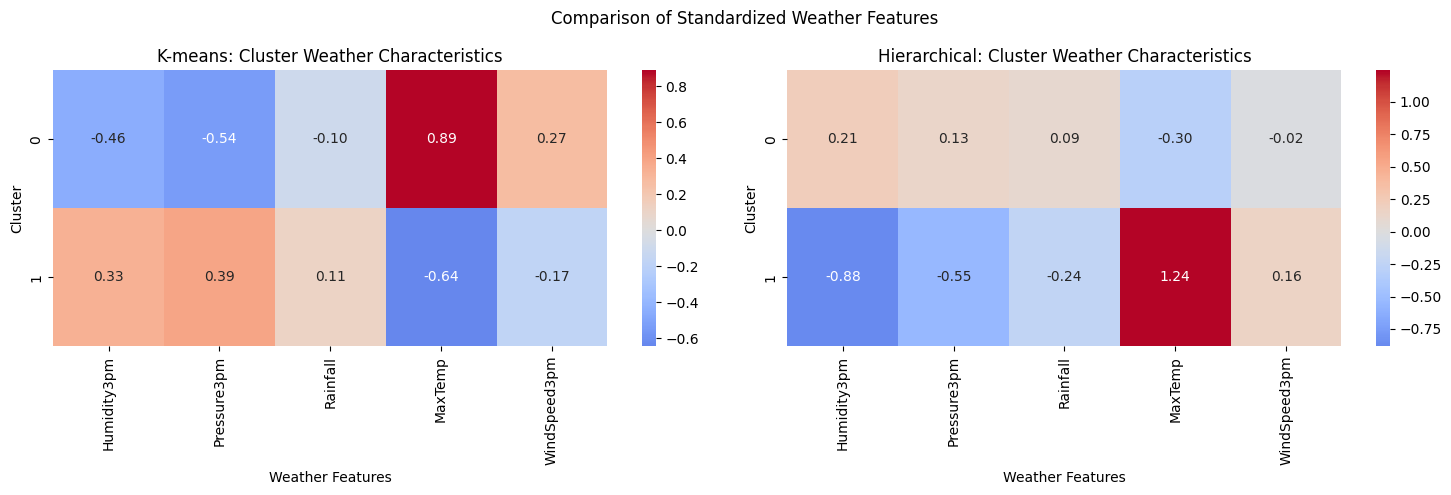

In [47]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# K-means feature heatmap
sns.heatmap(
    kmeans_feature_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[0]
)

axes[0].set_title("K-means: Cluster Weather Characteristics")
axes[0].set_xlabel("Weather Features")
axes[0].set_ylabel("Cluster")

# Hierarchical feature heatmap
sns.heatmap(
    hier_feature_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[1]
)

axes[1].set_title("Hierarchical: Cluster Weather Characteristics")
axes[1].set_xlabel("Weather Features")
axes[1].set_ylabel("Cluster")

plt.suptitle("Comparison of Standardized Weather Features")
plt.tight_layout()
plt.show()

### 6.6 Weather Pattern Interpretation

The cluster-level feature analysis reveals distinct weather characteristics associated with different rainfall patterns.

For K-means, Cluster 0 is characterized by higher temperatures (MaxTemp = 0.887), lower humidity (Humidity3pm = -0.456), and slightly lower rainfall (Rainfall = -0.096). This cluster has a RainTomorrow rate of 16.47%. In contrast, Cluster 1 exhibits lower temperatures (MaxTemp = -0.643), higher humidity (Humidity3pm = 0.330), and slightly higher rainfall (Rainfall = 0.114), with a higher RainTomorrow rate of 26.81%.

Hierarchical Clustering identifies a particularly distinct subgroup. Cluster 1 has substantially higher temperatures (MaxTemp = 1.243), lower humidity (Humidity3pm = -0.882), and lower rainfall (Rainfall = -0.241), with a RainTomorrow rate of only 7.76%. In comparison, Cluster 0 has cooler and more humid conditions and a RainTomorrow rate of 26.05%.

These findings suggest that both clustering algorithms identify weather patterns associated with differences in subsequent rainfall occurrence. Hierarchical Clustering produces a more distinct low-rainfall subgroup, while K-means generates more balanced clusters.

However, these relationships are descriptive rather than causal, and the cluster characteristics are based on selected standardized features rather than the complete feature set.

## Section 7 - Robustness Analysis

### 7.1 Experimental Design

To examine whether the clustering results are sensitive to random sampling, a robustness analysis is conducted using three different random seeds: 42, 123, and 2026.

For each seed, a stratified sample of 3,000 observations is selected from the preprocessed dataset.

Both K-means and Agglomerative Hierarchical Clustering are applied to the same sample with K=2, using identical evaluation metrics.

The purpose is to investigate whether the relative performance of the two algorithms remains consistent across different samples.

### 7.2 Robustness Evaluation

The clustering performance of both algorithms is evaluated across three independently generated stratified samples.

For each sample, the Silhouette Score, Calinski-Harabasz Index, and Davies-Bouldin Index are calculated.

The results are summarized to examine the consistency of the clustering performance across different random seeds.

In [48]:
# Robustness analysis using different random samples

seeds = [42, 123, 2026]
robustness_results = []

for seed in seeds:

    # Step 1: Stratified sampling
    X_sub, _, y_sub, _ = train_test_split(
        X,
        y,
        train_size=3000,
        stratify=y,
        random_state=seed
    )

    # Step 2: Define both clustering algorithms
    models = {
        "K-means": KMeans(
            n_clusters=2,
            random_state=42,
            n_init=10
        ),
        "Hierarchical": AgglomerativeClustering(
            n_clusters=2,
            linkage="ward"
        )
    }

    # Step 3: Fit and evaluate each model
    for algorithm, model in models.items():

        labels = model.fit_predict(X_sub)

        sil = silhouette_score(
            X_sub,
            labels,
            sample_size=1000,
            random_state=42
        )

        ch = calinski_harabasz_score(X_sub, labels)
        db = davies_bouldin_score(X_sub, labels)

        robustness_results.append({
            "Seed": seed,
            "Algorithm": algorithm,
            "Silhouette": sil,
            "Calinski-Harabasz": ch,
            "Davies-Bouldin": db
        })

# Create results table
robustness_df = pd.DataFrame(robustness_results)

display(robustness_df.round(4))

,Seed,Algorithm,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,42,K-means,0.1386,537.3882,2.2534
1,42,Hierarchical,0.1347,377.2871,2.1144
2,123,K-means,0.1479,569.1889,2.2028
3,123,Hierarchical,0.1259,444.2180,2.2935
4,2026,K-means,0.1467,532.8767,2.2727
5,2026,Hierarchical,0.1453,388.4052,2.1280


### 7.3 Summary Statistics

The mean and standard deviation of each evaluation metric are calculated across the three random samples.

A smaller standard deviation indicates that the corresponding metric varies less across the tested samples.

These statistics are used to assess the stability of each algorithm's clustering performance.

In [49]:
# Summarize robustness results

summary_df = robustness_df.groupby("Algorithm")[
    ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin"]
].agg(["mean", "std"])

display(summary_df.round(4))

Silhouette         Calinski-Harabasz          Davies-Bouldin  \
                   mean     std              mean      std           mean   
Algorithm                                                                   
Hierarchical     0.1353  0.0097          403.3034  35.8665         2.1786   
K-means          0.1444  0.0051          546.4846  19.7915         2.2430   

                      
                 std  
Algorithm             
Hierarchical  0.0997  
K-means       0.0361

### 7.4 Visualization of Robustness Results

The Silhouette Scores of K-means and Hierarchical Clustering are visualized across the three random samples to compare their stability and relative performance.

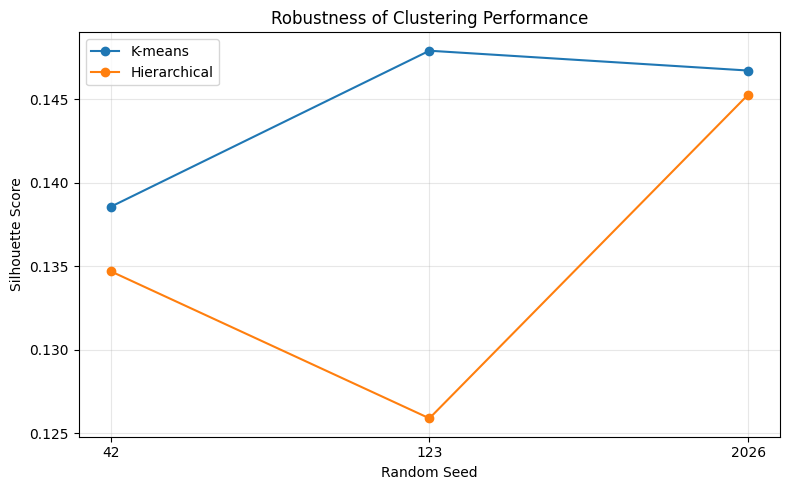

In [50]:
# Compare Silhouette Scores across random seeds

plt.figure(figsize=(8, 5))

for algorithm in ["K-means", "Hierarchical"]:

    subset = robustness_df[
        robustness_df["Algorithm"] == algorithm
    ]

    plt.plot(
        subset["Seed"].astype(str),
        subset["Silhouette"],
        marker="o",
        label=algorithm
    )

plt.title("Robustness of Clustering Performance")
plt.xlabel("Random Seed")
plt.ylabel("Silhouette Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.5 Results and Interpretation

The robustness analysis was conducted using three stratified samples of 3,000 observations with random seeds 42, 123, and 2026.

K-means consistently achieved higher Silhouette Scores and Calinski-Harabasz indices across all three samples. Its mean Silhouette Score was 0.1444, compared with 0.1353 for Hierarchical Clustering, while its mean Calinski-Harabasz Index was 546.4846, compared with 403.3034.

However, Hierarchical Clustering achieved a lower mean Davies-Bouldin Index (2.1786 vs. 2.2430), indicating that the two algorithms have different strengths depending on the evaluation metric.

K-means also showed lower standard deviations across all three metrics, suggesting more consistent performance under the tested sampling conditions.

Overall, the results provide additional support for selecting K-means (K=2) as the preferred clustering method. Nevertheless, the relatively low Silhouette Scores indicate weak cluster separation, and the analysis is limited to three random samples with K fixed at 2. Therefore, these findings provide preliminary evidence of robustness rather than a definitive assessment of clustering stability.

## Section 8 - Conclusion and Limitations

### 8.1 Conclusion

This study compared K-means and Agglomerative Hierarchical Clustering on stratified samples of the Australian weather dataset.

Among the tested cluster numbers (K=2–8), K=2 was preferred for both algorithms based on the internal evaluation metrics. K-means generally achieved higher Silhouette Scores and Calinski-Harabasz indices, while Hierarchical Clustering performed better under the Davies-Bouldin Index in the baseline comparison.

The robustness analysis across three random samples further supported K-means, which demonstrated more consistent evaluation results. Therefore, K-means (K=2) was selected as the preferred clustering configuration under the current experimental setup.

The cluster-level analysis also revealed meaningful differences in weather characteristics and subsequent rainfall rates. In particular, Hierarchical Clustering identified a smaller, hotter, and drier subgroup with a RainTomorrow rate of only 7.76%.

Overall, the findings suggest that unsupervised clustering can reveal interpretable weather patterns, although the relatively low Silhouette Scores indicate that the clusters are not strongly separated.

### 8.2 Limitations and Future Work

Several limitations should be considered.

First, the analysis was conducted using samples of 3,000 observations rather than the full dataset of 142,193 records. Although multiple random samples were evaluated, the results may not fully represent the complete dataset.

Second, the relatively low Silhouette Scores suggest that the weather observations do not form strongly separated clusters under the selected methods.

Third, the dataset contains standardized continuous features and one-hot encoded categorical variables. Since both algorithms rely on Euclidean-based clustering criteria, the feature representation may influence the clustering results.

Finally, the first two principal components explain only 37.69% of the total variance, limiting the information represented by the two-dimensional PCA visualization.

Future work could investigate alternative feature representations, larger samples, and additional clustering methods to assess the generalizability and stability of the findings.